In [1]:
import tensorflow as tf
from pathlib import Path
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

c:\Users\mrpar\AppData\Local\Programs\Python\Python310\lib\site-packages\google\api_core\_python_version_support.py:223: FutureWarning: You are using a non-supported Python version (3.10.11). Google will not post any further updates to google.api_core supporting this Python version. Please upgrade to the latest Python version, or at least Python 3.11, and then update google.api_core.
  warnings.warn(message, FutureWarning)


In [2]:
dataset_path = Path(
    r"C:\Users\mrpar\Downloads\Telegram Desktop\survillenceimagesexpanded"
)
print("Dataset exists:", dataset_path.exists())

Dataset exists: True


In [3]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.3,
    subset="training",
    seed=123,
    image_size=(224, 224),
    batch_size=16,
    label_mode="int"
)
val_test_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.3,
    subset="validation",
    seed=123,
    image_size=(224, 224),
    batch_size=16,
    label_mode="int"
)
class_names = train_ds.class_names
print("Classes:", class_names)

Found 1049 files belonging to 3 classes.
Using 735 files for training.
Found 1049 files belonging to 3 classes.
Using 314 files for validation.
Classes: ['dangerimagesexpanded', 'isolatedimagesexpanded', 'safeimagesexpanded']


In [4]:
val_size = int(0.5 * len(val_test_ds))
val_ds = val_test_ds.take(val_size)
test_ds = val_test_ds.skip(val_size)
print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Testing batches:", len(test_ds))

Training batches: 46
Validation batches: 10
Testing batches: 10


In [5]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

In [6]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomBrightness(0.2),
])

In [7]:
base_model = ResNet50(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

In [8]:
model = tf.keras.Sequential([
    data_augmentation,
    tf.keras.layers.Lambda(preprocess_input),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(3, activation="softmax")
])


In [11]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [12]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20
)

Epoch 1/20

46/46 ━━━━━━━━━━━━━━━━━━━━ 40s 702ms/step - accuracy: 0.4531 - loss: 1.2611 - val_accuracy: 0.5250 - val_loss: 1.0368
Epoch 2/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 30s 647ms/step - accuracy: 0.5782 - loss: 0.9417 - val_accuracy: 0.6187 - val_loss: 0.7766
Epoch 3/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 29s 638ms/step - accuracy: 0.6408 - loss: 0.8083 - val_accuracy: 0.7312 - val_loss: 0.6118
Epoch 4/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 30s 643ms/step - accuracy: 0.6898 - loss: 0.6916 - val_accuracy: 0.6938 - val_loss: 0.6232
Epoch 5/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 29s 626ms/step - accuracy: 0.7170 - loss: 0.6600 - val_accuracy: 0.7812 - val_loss: 0.5145
Epoch 6/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 30s 647ms/step - accuracy: 0.7129 - loss: 0.6187 - val_accuracy: 0.7875 - val_loss: 0.4857
Epoch 7/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 29s 629ms/step - accuracy: 0.7102 - loss: 0.6363 - val_accuracy: 0.7500 - val_loss: 0.5280
Epoch 8/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 28s 606ms/step - accuracy: 0.7510 - loss: 0.5604 - val_acc

In [ ]:
test_loss, test_acc = model.evaluate(test_ds)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 531ms/step - accuracy: 0.7987 - loss: 0.4384
Test Loss: 0.4384123980998993
Test Accuracy: 0.798701286315918
Test Accuracy: 79.87%


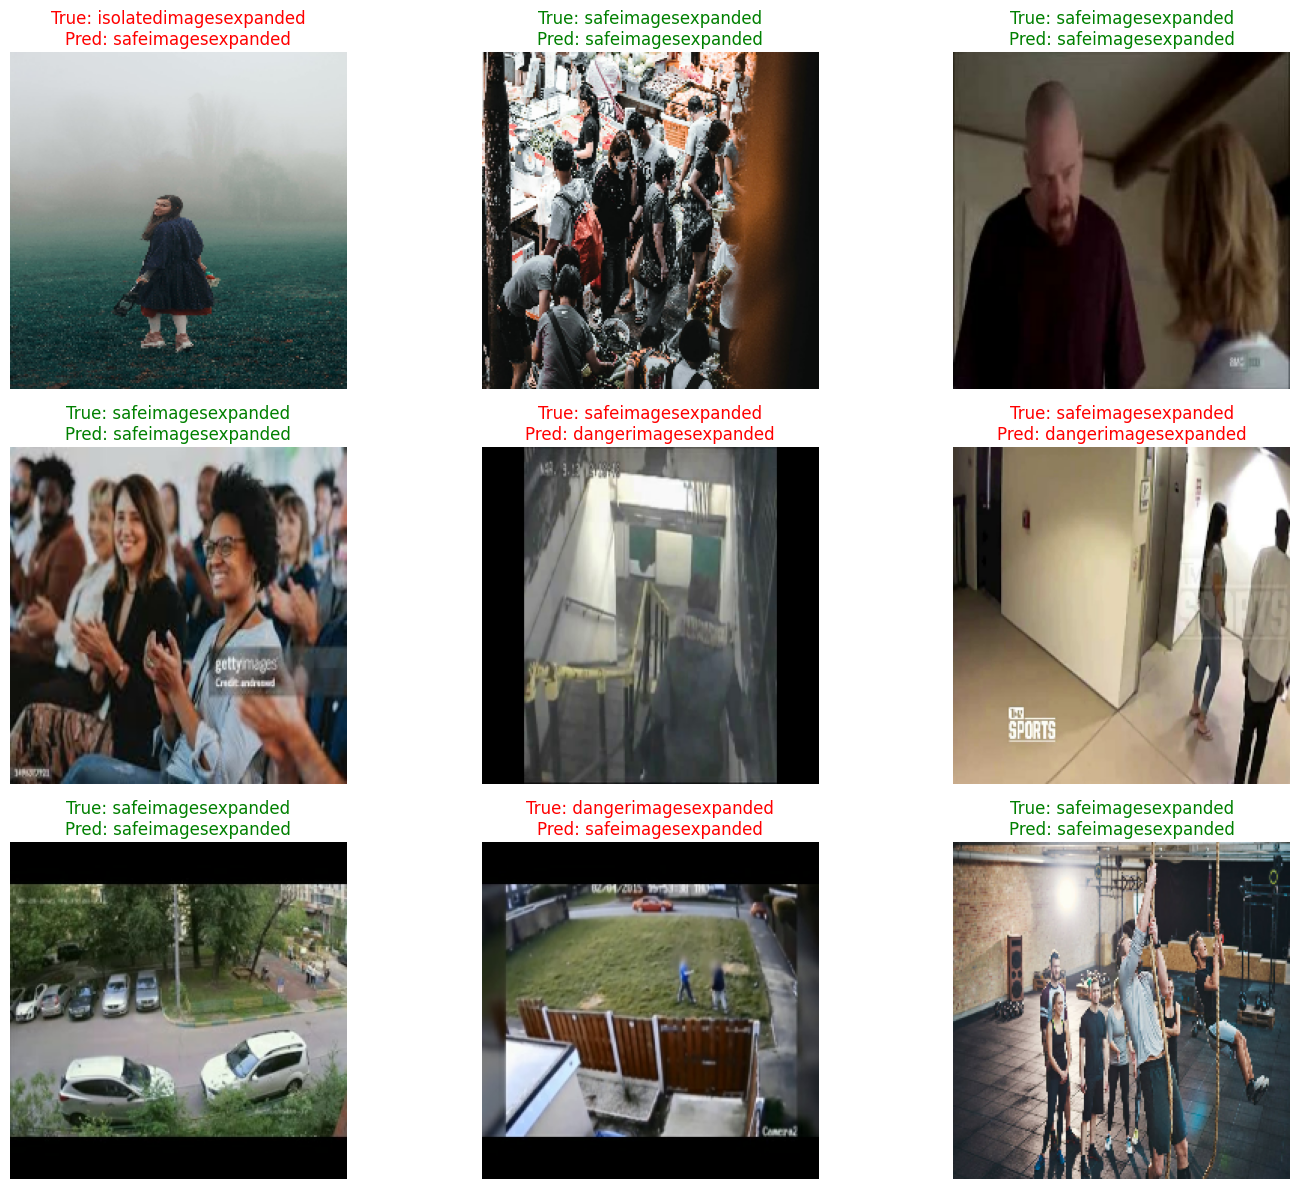

In [14]:
import matplotlib.pyplot as plt
import numpy as np
for images, labels in test_ds.take(1):
    predictions = model.predict(images, verbose=0)
    predicted_labels = np.argmax(predictions, axis=1)

    num_images = min(9, len(images))

    plt.figure(figsize=(15, 12))

    for i in range(num_images):
        plt.subplot(3, 3, i + 1)

        img = images[i].numpy().astype("uint8")
        plt.imshow(img)

        true_label = class_names[int(labels[i].numpy())]
        pred_label = class_names[predicted_labels[i]]

        color = "green" if true_label == pred_label else "red"

        plt.title(
            f"True: {true_label}\nPred: {pred_label}",
            color=color
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [15]:
model.save("resnet50_expanded_dataset.keras")

In [16]:
# Fine tuning ResNet50
# Unfreeze the ResNet50 base model
base_model.trainable = True
# Freezing earlier layers and fine tuning only the last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 50s 869ms/step - accuracy: 0.7714 - loss: 0.5621 - val_accuracy: 0.8125 - val_loss: 0.4275
Epoch 2/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 38s 832ms/step - accuracy: 0.8231 - loss: 0.4371 - val_accuracy: 0.8250 - val_loss: 0.4097
Epoch 3/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 38s 830ms/step - accuracy: 0.8435 - loss: 0.4002 - val_accuracy: 0.7812 - val_loss: 0.5045
Epoch 4/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 38s 824ms/step - accuracy: 0.8748 - loss: 0.3355 - val_accuracy: 0.8375 - val_loss: 0.4166
Epoch 5/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 39s 843ms/step - accuracy: 0.8884 - loss: 0.3303 - val_accuracy: 0.8687 - val_loss: 0.3587
Epoch 6/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 39s 842ms/step - accuracy: 0.8912 - loss: 0.3082 - val_accuracy: 0.8188 - val_loss: 0.4636
Epoch 7/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 39s 848ms/step - accuracy: 0.8776 - loss: 0.3084 - val_accuracy: 0.8813 - val_loss: 0.3426
Epoch 8/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 38s 830ms/step - accuracy: 0.9184 - loss: 0.2502 - val_accu

In [17]:
# Evaluating fine tuning model
finetuned_test_loss, finetuned_test_acc = model.evaluate(test_ds)
print("Fine-tuned Test Loss:", finetuned_test_loss)
print("Fine-tuned Test Accuracy:", finetuned_test_acc)
print(f"Fine-tuned Test Accuracy: {finetuned_test_acc * 100:.2f}%")

10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 534ms/step - accuracy: 0.8377 - loss: 0.3472
Fine-tuned Test Loss: 0.34720441699028015
Fine-tuned Test Accuracy: 0.8376623392105103
Fine-tuned Test Accuracy: 83.77%


In [18]:
model.save("resnet50_expanded_dataset_finetuned.keras")